# Phase 3 · Rhetorical Role Prediction

<div align="center">

## MODEL4 · LoRMA+

**Mandatory adaptation experiment**

`CS781 Capstone` &nbsp; · &nbsp; `Corporate Law + IT` &nbsp; · &nbsp; `Sentence classification`

</div>

---

### Experiment at a glance

| Item | Configuration |
|:--|:--|
| **Phase 1 backbone** | `model4(2).ipynb` |
| **Architecture** | RoPE, RMSNorm, sink/window attention, GQA and alternating bottleneck feed-forward layers |
| **Representation size** | 560-dimensional hidden states |
| **Adaptation method** | LoRMA+ (matrix multiplication with identity inflation) |
| **Checkpoint selection** | Development Macro-F1 |
| **Domains** | Corporate Law (CL) and Information Technology (IT) |

> **Objective**
>
> Uses a low-rank multiplicative parameterization on selected attention projections. The model predicts exactly one rhetorical-role label per sentence while preserving document order.

### Before you run

1. Attach the **matching Phase 1 artifacts** as a Kaggle input dataset.
2. Set `ASSET_DIR` in the setup cell to that dataset's directory.
3. Confirm it contains `pytorch_model.bin` and `custom_bpe_scratch.json`.
4. Enable internet access and add a Kaggle Secret named `HF` containing a Hugging Face read token with access to `Exploration-Lab/CS-781-Capstone`.

> **Checkpoint safety:** Model 2 and Model 4 checkpoints/tokenizers are not interchangeable. This notebook uses the architecture and tokenizer implementation from its matching Phase 1 notebook; it does not use an external pretrained language model.

### Notebook workflow

`Setup` → `Tokenizer` → `Backbone` → `Data` → `Adaptation` → `Training & validation` → `Predictions`

---

**Run cells from top to bottom.** Training has not been executed in this environment, so no performance scores are claimed.


> **Hugging Face access required:** enable Kaggle internet and the `HF` secret with read access to the dataset. Attach the matching Model 4 Phase-1 checkpoint and tokenizer as a Kaggle Input.


In [1]:
import json, os, random, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
ASSET_DIR = Path('/kaggle/input/datasets/kalyanbabuk/phase1m4/')
MODEL_FAMILY = 'model4'
OUTPUT_DIR = Path('/kaggle/working/phase3_rr_model4_lorma')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VOCAB_SIZE = 32000
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048
MAX_LENGTH = 256
BATCH_SIZE = 4
EPOCHS = 8
WEIGHT_DECAY = 0.01
DROPOUT = 0.15
GRAD_CLIP = 1.0
GRAD_ACCUM_STEPS = 4  # effective batch size = 16
WARMUP_RATIO = 0.1
PATIENCE = 3
USE_CLASS_WEIGHTS = True  # bounded inverse-square-root weights from train only
USE_GRAD_CHECKPOINTING = True
AMP_DTYPE = torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16
DOMAIN = 'both' 
USE_PREVIOUS_SENTENCE_CONTEXT = True

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Authenticate with a Kaggle Secret named HF. Never paste a real token into a notebook.
def get_hf_token():
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if token:
        return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF")
    except Exception:
        token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token (input hidden): ").strip()
    if not token:
        raise RuntimeError(
            "A Hugging Face token is required. In Kaggle, add a secret named 'HF' "
            "containing your token and enable access to secrets for this notebook."
        )
    return token

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
from huggingface_hub import hf_hub_download
print("Hugging Face authentication configured for", HF_DATASET_REPO)

def locate_asset(filename):
    root = Path(ASSET_DIR)
    if not root.exists():
        raise FileNotFoundError(f'Attach the matching Phase-1 asset dataset and set ASSET_DIR. Missing: {root}')
    hits = list(root.rglob(filename))
    if not hits:
        raise FileNotFoundError(f'{filename} not found below {root}')
    if len(hits) > 1:
        raise ValueError(f'Ambiguous asset {filename}: {hits}; set ASSET_DIR to one checkpoint directory.')
    return hits[0]

def fetch_json(path):
    """Download a Phase-3 JSON file from the private Hugging Face dataset repo."""
    try:
        local_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=path,
            repo_type="dataset",
            token=HF_TOKEN,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download {path} from {HF_DATASET_REPO}. Check that your Hugging Face "
            "token is valid, has read access to the repository, and that the HF secret is "
            "named exactly 'HF' in Kaggle. Also verify that the file path exists in the repo. "
            f"Original error: {exc}"
        ) from exc
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)

def records_from_payload(payload, labeled=True):
    if isinstance(payload, dict):
        if 'text' in payload and 'id' in payload:
            docs = [payload]
        else:
            docs = []
            for did, v in payload.items():
                if isinstance(v, dict):
                    r = dict(v)
                    r.setdefault('id', str(did))
                    docs.append(r)
                else:
                    docs.append({'id': str(did), 'text': v})
    elif isinstance(payload, list):
        docs = payload
    else:
        raise ValueError('Unsupported payload type ' + str(type(payload)))
    out = []
    seen_ids = set()
    for d in docs:
        did = str(d.get('id', d.get('document_id', d.get('doc_id', ''))))
        if not did or did in seen_ids:
            raise ValueError(f'Missing or duplicate document ID: {did!r}')
        seen_ids.add(did)
        ss = d.get('text', d.get('sentences', []))
        if isinstance(ss, str):
            ss = [ss]
        labs = d.get('labels', []) if labeled else None
        if labeled and (not isinstance(labs, list) or len(labs) != len(ss)):
            raise ValueError(f'{did}: label/sentence length mismatch')
        for i, s in enumerate(ss):
            out.append({'doc_id': did, 'sent_idx': i, 'sentence': str(s), 'label': labs[i] if labeled else None, 'sentences': ss})
    return out

def label_names_from_vocab(v):
    if isinstance(v, list):
        return list(map(str, v))
    if isinstance(v, dict):
        if all((isinstance(x, int) for x in v.values())):
            return [k for k, _ in sorted(v.items(), key=lambda kv: kv[1])]
        if all((str(k).isdigit() for k in v)):
            return [str(x) for k, x in sorted(v.items(), key=lambda kv: int(kv[0]))]
        return list(v.keys())
    raise ValueError('Unsupported label_vocab structure')

def context_text(r):
    """Human-readable context; only previous sentence plus the target are used."""
    ss = r['sentences']
    i = r['sent_idx']
    if not USE_PREVIOUS_SENTENCE_CONTEXT or i == 0:
        return ss[i]
    return 'Previous sentence: ' + ss[i - 1] + '\nTarget sentence: ' + ss[i]

class RRDataset(Dataset):
    """Sentence-level examples with an explicit mask for target-sentence tokens."""
    def __init__(self, records, tokenizer, label_to_id, labeled=True):
        self.records = records
        self.tokenizer = tokenizer
        self.label_to_id = label_to_id
        self.labeled = labeled
        self.encoded = {}

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        if i in self.encoded:
            return self.encoded[i]
        r = self.records[i]
        target_ids = self.tokenizer.encode(r['sentence'])
        if not target_ids:
            target_ids = [1]
        # Preserve the beginning and ending of overlong targets; context uses leftover space.
        if len(target_ids) > MAX_LENGTH:
            target_ids = target_ids[:MAX_LENGTH // 2] + target_ids[-(MAX_LENGTH - MAX_LENGTH // 2):]
        remaining = max(0, MAX_LENGTH - len(target_ids))
        prefix_ids = []
        if remaining and USE_PREVIOUS_SENTENCE_CONTEXT and r['sent_idx'] > 0:
            prefix = 'Previous sentence: ' + r['sentences'][r['sent_idx'] - 1] + '\nTarget sentence: '
            prefix_ids = self.tokenizer.encode(prefix)[-remaining:]
        ids = prefix_ids + target_ids
        target_start = len(prefix_ids)
        target_mask = [False] * target_start + [True] * len(target_ids)
        x = {'input_ids': ids, 'target_mask': target_mask, 'record': r}
        if self.labeled:
            if r['label'] not in self.label_to_id:
                raise ValueError(f"Unknown label {r['label']!r} for document {r['doc_id']} sentence {r['sent_idx']}")
            x['label'] = self.label_to_id[r['label']]
        self.encoded[i] = x
        return x

def collate_rr(batch):
    n = max(len(x['input_ids']) for x in batch)
    ids = torch.zeros((len(batch), n), dtype=torch.long)
    mask = torch.zeros((len(batch), n), dtype=torch.bool)
    target_mask = torch.zeros((len(batch), n), dtype=torch.bool)
    for i, x in enumerate(batch):
        length = len(x['input_ids'])
        ids[i, :length] = torch.tensor(x['input_ids'], dtype=torch.long)
        mask[i, :length] = True
        target_mask[i, :length] = torch.tensor(x['target_mask'], dtype=torch.bool)
        if not target_mask[i].any():
            raise RuntimeError('Target token mask is empty; refusing to train on an invalid example.')
    labels = torch.tensor([x['label'] for x in batch], dtype=torch.long) if 'label' in batch[0] else None
    return ids, mask, target_mask, labels, [x['record'] for x in batch]

class SentenceClassifier(nn.Module):
    def __init__(self, backbone, hidden_size, num_labels):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, ids, mask, target_mask):
        h = self.backbone.forward_hidden(ids, attention_mask=mask)
        weights = target_mask.to(h.dtype).unsqueeze(-1)
        pooled = (h.float() * weights.float()).sum(dim=1) / weights.float().sum(dim=1).clamp_min(1.0)
        last = mask.long().sum(dim=1) - 1
        pooled = 0.5 * (pooled + h[torch.arange(h.size(0), device=h.device), last].float())
        return self.classifier(self.dropout(pooled))

def evaluate(model, loader, nlabels):
    model.eval()
    ys, ps = [], []
    tot, n = 0.0, 0
    with torch.no_grad():
        for ids, mask, target_mask, y, _ in loader:
            ids, mask, target_mask, y = ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                z = model(ids, mask, target_mask)
            tot += manual_cross_entropy(z, y, reduction='sum').item()
            n += y.numel()
            ys.extend(y.cpu().tolist())
            ps.extend(z.argmax(-1).cpu().tolist())
    labels = list(range(nlabels))
    return ({'loss': tot / max(n, 1),
             'macro_f1': f1_score(ys, ps, average='macro', labels=labels, zero_division=0),
             'macro_precision': precision_score(ys, ps, average='macro', labels=labels, zero_division=0),
             'macro_recall': recall_score(ys, ps, average='macro', labels=labels, zero_division=0)}, ys, ps)


# Basic tensor operations only for task losses; no fused attention/Transformer APIs.
def manual_log_softmax(x):
    x = x.float()
    x = x - x.amax(dim=-1, keepdim=True)
    return x - x.exp().sum(dim=-1, keepdim=True).log()

def manual_cross_entropy(logits, targets, weights=None, reduction='mean'):
    losses = -manual_log_softmax(logits).gather(-1, targets[:, None]).squeeze(-1)
    if weights is not None:
        losses = losses * weights[targets]
    return losses.sum() if reduction == 'sum' else losses.mean()

def run_config(model):
    return dict(model_family=MODEL_FAMILY, vocab_size=VOCAB_SIZE, hidden_size=N_EMBD,
                layers=len(model.backbone.layers),
                heads=N_HEAD, kv_heads=N_KV_HEAD, model_context=MODEL_CONTEXT_LENGTH,
                max_length=MAX_LENGTH, previous_context=USE_PREVIOUS_SENTENCE_CONTEXT,
                pooling='target_mean_and_last_average', dropout=DROPOUT, seed=SEED,
                method='LoRMA+', rank=RANK, alpha=ALPHA, adapter_dropout=ADAPTER_DROPOUT,
                target_modules=list(TARGET_MODULES), lr_adapter=LR_BACKBONE, lr_head=LR_HEAD,
                gradient_accumulation=GRAD_ACCUM_STEPS, class_balance=USE_CLASS_WEIGHTS,
                tokenizer_file='custom_bpe_scratch.json')

def make_optimizer(model):
    groups = []
    for is_head, lr in [(False, LR_BACKBONE), (True, LR_HEAD)]:
        for decay in [False, True]:
            params = [p for n,p in model.named_parameters() if p.requires_grad
                      and n.startswith('classifier.') == is_head and (p.ndim >= 2) == decay]
            if params:
                groups.append({'params': params, 'lr': lr, 'weight_decay': WEIGHT_DECAY if decay else 0.0})
    return torch.optim.AdamW(groups)

def train_model(model, train_loader, dev_loader, label_names, optimizer, extra_loss=None,
                checkpoint_name='best_rr_checkpoint.pt'):
    if not len(train_loader) or not len(dev_loader):
        raise ValueError('Training and development splits must be non-empty.')
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda' and AMP_DTYPE == torch.float16)
    best, stale, hist = -1.0, 0, []
    ckpt_path = OUTPUT_DIR / checkpoint_name
    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = max(1, round(WARMUP_RATIO * total_steps))
    base_lrs = [g['lr'] for g in optimizer.param_groups]
    step = 0
    for ep in range(1, EPOCHS + 1):
        model.train()
        running, seen = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        for batch_idx, (ids, mask, target_mask, y, records) in enumerate(train_loader):
            ids, mask = ids.to(DEVICE), mask.to(DEVICE)
            target_mask, y = target_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                logits = model(ids, mask, target_mask)
                loss = manual_cross_entropy(logits, y, CLASS_WEIGHTS)
                if extra_loss is not None:
                    loss = extra_loss(loss, logits, records)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {ep}')
            # Normalize by actual example count, including the last partial accumulation group.
            group_start = (batch_idx // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS
            group_examples = min(GRAD_ACCUM_STEPS * train_loader.batch_size,
                                 len(train_loader.dataset) - group_start * train_loader.batch_size)
            scaler.scale(loss * y.numel() / group_examples).backward()
            if (batch_idx + 1) % GRAD_ACCUM_STEPS == 0 or batch_idx + 1 == len(train_loader):
                scale = ((step + 1) / warmup_steps if step < warmup_steps else
                         0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps))))
                for g, lr in zip(optimizer.param_groups, base_lrs):
                    g['lr'] = lr * scale
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                step += 1
            running += float(loss.detach()) * y.numel()
            seen += y.numel()
        met, _, _ = evaluate(model, dev_loader, len(label_names))
        hist.append({'epoch': ep, 'train_loss': running / seen, **met})
        print(f"epoch={ep} train_loss={running / seen:.4f} dev_macro_f1={met['macro_f1']:.4f}")
        if met['macro_f1'] > best:
            best, stale = met['macro_f1'], 0
            torch.save({'model_state_dict': {k: v.detach().cpu() for k,v in model.state_dict().items()},
                        'epoch': ep, 'metrics': met, 'label_names': label_names,
                        'config': run_config(model)}, ckpt_path)
        else:
            stale += 1
        if stale >= PATIENCE:
            print('Early stopping; restoring best development Macro-F1 checkpoint.')
            break
    ck = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model_state_dict'], strict=True)
    del ck
    with open(OUTPUT_DIR / (Path(checkpoint_name).stem + '_history.json'), 'w') as f:
        json.dump(hist, f, indent=2)
    plt.figure(figsize=(7, 4))
    plt.plot([x['epoch'] for x in hist], [x['train_loss'] for x in hist], marker='o', label='train objective')
    plt.plot([x['epoch'] for x in hist], [x['loss'] for x in hist], marker='o', label='dev unweighted CE')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (Path(checkpoint_name).stem + '_loss_curve.png'), dpi=150)
    plt.show()
    return model, hist, ckpt_path

def save_predictions(model, records, label_names, label_to_id, suffix):
    loader = DataLoader(RRDataset(records, tokenizer, label_to_id, False), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=collate_rr)
    pred = {}
    model.eval()
    with torch.no_grad():
        for ids, mask, target_mask, _, rs in loader:
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == 'cuda'):
                ys = model(ids.to(DEVICE), mask.to(DEVICE), target_mask.to(DEVICE)).argmax(-1).cpu().tolist()
            for r, y in zip(rs, ys):
                pred.setdefault(r['doc_id'], {})[r['sent_idx']] = label_names[y]
    ordered = {}
    for r in records:
        if r['doc_id'] not in ordered:
            ordered[r['doc_id']] = [None] * len(r['sentences'])
        ordered[r['doc_id']][r['sent_idx']] = pred[r['doc_id']][r['sent_idx']]
    assert all(x is not None for vv in ordered.values() for x in vv), 'Prediction output has missing sentence labels.'
    p = OUTPUT_DIR / f'{suffix}_prediction.json'
    json.dump(ordered, open(p, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    return p


Device: cuda
Hugging Face authentication configured for Exploration-Lab/CS-781-Capstone


## 1. Phase-1 custom byte-level BPE tokenizer

Exact tokenizer class extracted from the matching Phase-1 notebook.

In [2]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

# Notes preserved from the original cell:
# Base vocabulary of all 256 individual bytes
# Reserved Special Tokens
# 1. Chunk texts to prevent massive contiguous memory blocks
# Split into words and whitespace blocks to keep sequence lengths small
# 2. Drop singletons to massively save RAM
# Initialize splits: word -> list of byte integers
# 3. Build fast inverted index
# Record the merge
# 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
# Remove old pairs associated with this word from global tracking
# Execute the merge on this word's internal list
# Add newly formed pairs back to global tracking
# Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents


## 2. Phase-1 model architecture

Exact custom model classes from the supplied notebook; only original model instantiation is omitted.

In [3]:
class ManualSiLU(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)

class ManualGELU(nn.Module):
    def forward(self, x):
        return (0.5 * x.float() * (1.0 + torch.erf(x.float() / math.sqrt(2.0)))).to(x.dtype)

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        norm = xf * torch.rsqrt(xf.square().mean(-1, keepdim=True) + self.eps)
        return (norm * self.weight.float()).to(x.dtype)


def precompute_rope(dim, max_len, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(max_len)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rope(xq, xk, freqs_cis):
    xq_complex = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_complex = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_complex.shape[1], 1, xq_complex.shape[-1])
    xq_out = torch.view_as_real(xq_complex * freqs_cis).flatten(3).type_as(xq)
    xk_out = torch.view_as_real(xk_complex * freqs_cis).flatten(3).type_as(xk)
    return (xq_out, xk_out)

class SinkWindowAttention(nn.Module):

    def __init__(self, head_dim, window_size=256, sink_size=4):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)
        self.window_size = window_size
        self.sink_size = sink_size

    def create_sink_window_mask(self, L_q, L_k, device):
        row_indices = (torch.arange(L_q, device=device) + (L_k - L_q)).unsqueeze(1)
        causal_mask = torch.arange(L_k, device=device).unsqueeze(0) <= row_indices
        col_indices = torch.arange(L_k, device=device).unsqueeze(0)
        window_mask = row_indices - col_indices < self.window_size
        mask = causal_mask & window_mask
        if self.sink_size > 0:
            sink_mask = torch.zeros(L_q, L_k, dtype=torch.bool, device=device)
            sink_mask[:, :self.sink_size] = True
            sink_mask = sink_mask & causal_mask
            mask = mask | sink_mask
        return mask.view(1, 1, L_q, L_k)

    def forward(self, q, k, v, is_causal=True, attention_mask=None):
        L_q, L_k = (q.shape[2], k.shape[2])
        with torch.autocast(device_type=q.device.type, enabled=False):
            scores = torch.matmul(q.float(), k.float().transpose(-2, -1)) * self.scale
        if is_causal:
            mask = self.create_sink_window_mask(L_q, L_k, q.device)
            scores = scores.masked_fill(~mask, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = (scores - scores.amax(dim=-1, keepdim=True)).exp()
        weights = weights / weights.sum(dim=-1, keepdim=True).clamp_min(1e-20)
        return torch.matmul(weights.to(v.dtype), v)

class EfficientGQA(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads, window_size=256, sink_size=4):
        super().__init__()
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.head_dim = dim // n_heads
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.attention = SinkWindowAttention(self.head_dim, window_size, sink_size)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.wq(x).view(B, L, self.n_heads, self.head_dim)
        k = self.wk(x).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rope(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_cache = (k, v)
        k = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.attention(q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2), is_causal=True, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_cache)

class StandardFFN(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), ManualGELU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x):
        return self.net(x)

class BottleneckFFN(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim // 4, bias=False), ManualGELU(), nn.Linear(dim // 4, dim, bias=False))

    def forward(self, x):
        return self.net(x)

class EfficientTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads, window_size, sink_size, is_bottleneck=False):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.attn = EfficientGQA(dim, n_heads, n_kv_heads, window_size, sink_size)
        self.norm2 = RMSNorm(dim)
        if is_bottleneck:
            self.ffn = BottleneckFFN(dim)
        else:
            self.ffn = StandardFFN(dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return (x, new_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_len, window_size=256, sink_size=4):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([EfficientTransformerBlock(dim=dim, n_heads=n_heads, n_kv_heads=n_kv_heads, window_size=window_size, sink_size=sink_size, is_bottleneck=i % 2 != 0) for i in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.embeddings.weight
        self.register_buffer('freqs_cis', precompute_rope(dim // n_heads, max_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        x = self.embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache = kv_caches[i] if kv_caches is not None else None
            x, new_cache = layer(x, freqs_cis, cache, attention_mask=attention_mask)
            new_caches.append(new_cache)
        logits = self.output(self.norm(x))
        return (logits, new_caches)

# Notes preserved from the original cell:
# ==========================================
# 4. Model Architecture (Model 4: Sink + Window + Bottleneck + Masking)
# ==========================================
# NEW: Added attention_mask parameter
# NEW: Apply the padding mask passed down from the generation loop
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to SinkWindowAttention
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to EfficientGQA
# NEW: Added attention_mask parameter
# NEW: Pass attention_mask to EfficientTransformerBlock


In [4]:
N_EMBD = 560
MODEL_CONTEXT_LENGTH = 2048
backbone = CustomLegalModel(VOCAB_SIZE, N_EMBD, N_LAYER, N_HEAD, N_KV_HEAD, MODEL_CONTEXT_LENGTH)

def _forward_hidden(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
    B, L = tokens.shape
    freqs_cis = torch.view_as_complex(self.freqs_cis[start_pos:start_pos + L].to(tokens.device))
    h = self.embeddings(tokens)
    for layer in self.layers:
        if self.training and USE_GRAD_CHECKPOINTING and torch.is_grad_enabled():
            from torch.utils.checkpoint import checkpoint
            # Bind layer now: backward recomputation must not capture the final loop value.
            def block_forward(x, block=layer):
                return block(x, freqs_cis, kv_cache=None, attention_mask=attention_mask)[0]
            h = checkpoint(block_forward, h, use_reentrant=False)
        else:
            h, _ = layer(h, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return self.norm(h)
backbone.forward_hidden = _forward_hidden.__get__(backbone, CustomLegalModel)
checkpoint_path = locate_asset('pytorch_model.bin')
tokenizer_path = locate_asset('custom_bpe_scratch.json')
state = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
if isinstance(state, dict) and 'model_state_dict' in state:
    state = state['model_state_dict']
backbone.load_state_dict(state, strict=True)
del state  # do not retain a second complete CPU state dict
tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(str(tokenizer_path))
print('Loaded matching Model4 checkpoint:', checkpoint_path, 'tokenizer:', tokenizer_path)

assert MAX_LENGTH <= MODEL_CONTEXT_LENGTH
assert max(tokenizer.vocab) < VOCAB_SIZE, 'Tokenizer IDs exceed embedding vocabulary.'


Loaded matching Model4 checkpoint: /kaggle/input/datasets/kalyanbabuk/phase1m4/pytorch_model.bin tokenizer: /kaggle/input/datasets/kalyanbabuk/phase1m4/custom_bpe_scratch.json


## 3. Phase-3 data and sentence examples

Development Macro-F1 is used for model selection. Both domains are enabled by default.

In [5]:
data = {k: fetch_json(v) for k, v in {'CL_train': 'Phase_3_RR/Train/CL_train.json', 'IT_train': 'Phase_3_RR/Train/IT_train.json', 'CL_dev': 'Phase_3_RR/Train/CL_dev.json', 'IT_dev': 'Phase_3_RR/Train/IT_dev.json', 'label_vocab': 'Phase_3_RR/Train/label_vocab.json', 'CL_test': 'Phase_3_RR/Test/CL_test.json', 'IT_test': 'Phase_3_RR/Test/IT_test.json'}.items()}
label_names = label_names_from_vocab(data['label_vocab'])
label_to_id = {v: i for i, v in enumerate(label_names)}
keys = ['CL', 'IT'] if DOMAIN == 'both' else [DOMAIN]
train_records = sum((records_from_payload(data[k + '_train'], True) for k in keys), [])
dev_records = sum((records_from_payload(data[k + '_dev'], True) for k in keys), [])
test_records = sum((records_from_payload(data[k + '_test'], False) for k in keys), [])
train_loader = DataLoader(RRDataset(train_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_rr)
dev_loader = DataLoader(RRDataset(dev_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
print('Labels:', label_names)
print('Train/dev/test sentences:', len(train_records), len(dev_records), len(test_records))

assert train_records and dev_records and test_records
assert len(label_names) == len(set(label_names))
for domain in keys:
    train_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_train'], True)}
    dev_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_dev'], True)}
    test_ids = {r['doc_id'] for r in records_from_payload(data[domain + '_test'], False)}
    assert not (train_ids & dev_ids or train_ids & test_ids or dev_ids & test_ids), f'{domain}: split overlap'
counts = torch.bincount(torch.tensor([label_to_id[r['label']] for r in train_records]), minlength=len(label_names)).float()
print('Train label support:', dict(zip(label_names, counts.int().tolist())))
if (counts == 0).any(): print('WARNING: some official classes have no training examples.')
weights = (counts.sum() / (len(label_names) * counts.clamp_min(1))).sqrt().clamp(0.5, 3.0)
weights /= (weights * counts).sum() / counts.sum()
CLASS_WEIGHTS = weights.to(DEVICE) if USE_CLASS_WEIGHTS else None

for split in ['train', 'dev', 'test']:
    all_ids = []
    for domain in keys:
        rr = records_from_payload(data[domain + '_' + split], split != 'test')
        all_ids += list(dict.fromkeys(r['doc_id'] for r in rr))
    if len(all_ids) != len(set(all_ids)):
        raise ValueError(f'{split}: document IDs collide across domains; use separate domain runs.')


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
Train/dev/test sentences: 16845 2142 2197
Train label support: {'Fact': 4098, 'Issue': 107, 'ArgumentPetitioner': 1613, 'ArgumentRespondent': 1348, 'Statute': 1099, 'Dissent': 284, 'PrecedentReliedUpon': 1945, 'PrecedentNotReliedUpon': 569, 'PrecedentOverruled': 3, 'RulingByLowerCourt': 874, 'RatioOfTheDecision': 4301, 'RulingByPresentCourt': 307, 'None': 297}


## 4. LoRMA+ with additive rank inflation

The original element-wise modulation was not the LoRMA formulation in the paper.
This implementation uses equation (8) from [Bihany et al., ACL 2025](https://aclanthology.org/2025.findings-acl.527.pdf):

$$W_{\mathrm{eff}} = (I_d + (\alpha/r)BA)W_0,$$

where $W_0$ is $d\times k$, $A$ is $r\times d$, and $B$ is $d\times r$.
With row-vector batches, compute $z=xW_0^T$, then $y=z+(\alpha/r)(zA^T)B^T$.
This avoids constructing a dense $d\times d$ adaptation matrix. $B=0$ initially, preserving the Phase-1 output exactly.

Only the Q/K/V/output projection adapters and sentence-classification head train.
The Phase-1 weights remain frozen, but autograd must propagate through them so earlier adapters receive gradients.
Adapter dropout is applied to the projected activations on the update branch (a regularization choice); the exact equation holds at evaluation or with dropout zero.


In [6]:
METHOD = 'LoRMA+'
LR_BACKBONE = 2e-4  # adapter learning rate; frozen base parameters are excluded
LR_HEAD = 5e-4
RANK = 8
ALPHA = 8.0
ADAPTER_DROPOUT = 0.05
TARGET_MODULES = ('wq', 'wk', 'wv', 'wo')

class LORMALinear(nn.Module):
    """LoRMA+, paper Eq. (8): W_eff = (I_out + alpha/rank * B @ A) @ W0."""
    def __init__(self, base, rank=RANK, alpha=ALPHA, dropout=ADAPTER_DROPOUT):
        super().__init__()
        if not isinstance(base, nn.Linear):
            raise TypeError('Expected an unwrapped nn.Linear projection.')
        if not 0 < rank <= min(base.in_features, base.out_features):
            raise ValueError('Invalid adapter rank.')
        self.base = base
        for p in self.base.parameters(): p.requires_grad_(False)
        self.rank, self.alpha = rank, float(alpha)
        self.scale = float(alpha) / rank
        self.drop = nn.Dropout(dropout)
        # Left multiplication acts in OUTPUT space, including rectangular K/V weights.
        self.A = nn.Parameter(base.weight.new_empty(rank, base.out_features))
        self.B = nn.Parameter(base.weight.new_zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        # Do not wrap this in no_grad: gradients must reach preceding adapters.
        projected = x @ self.base.weight.transpose(0, 1)
        update = (self.drop(projected) @ self.A.transpose(0, 1)) @ self.B.transpose(0, 1)
        out = projected + self.scale * update
        if self.base.bias is not None:
            out = out + self.base.bias  # frozen bias is not part of the weight transform
        return out

    @torch.no_grad()
    def merged_weight(self):
        """Equivalent eval weight for testing/export; does not modify the frozen base."""
        w = self.base.weight.float()
        return w + self.scale * (self.B.float() @ (self.A.float() @ w))

def adapt(b, rank=RANK, alpha=ALPHA, dropout=ADAPTER_DROPOUT, targets=TARGET_MODULES):
    for layer in b.layers:
        for name in targets:
            if not isinstance(getattr(layer.attn, name), nn.Linear):
                raise ValueError(f'{name} is already adapted or is not a linear projection.')
    for p in b.parameters(): p.requires_grad_(False)
    for layer in b.layers:
        for name in targets:
            setattr(layer.attn, name, LORMALinear(getattr(layer.attn, name), rank, alpha, dropout))
    return b

def load_lorma_checkpoint(path, device=DEVICE):
    """Rebuild full frozen Model-4 layout and adapters, then load all saved weights strictly."""
    ck = torch.load(path, map_location='cpu', weights_only=False)
    cfg = ck['config']
    if cfg['model_family'] != 'model4' or cfg['method'] != 'LoRMA+':
        raise ValueError('Not a Model-4 LoRMA+ checkpoint.')
    b = CustomLegalModel(cfg['vocab_size'], cfg['hidden_size'], cfg['layers'],
                         cfg['heads'], cfg['kv_heads'], cfg['model_context'])
    b.forward_hidden = _forward_hidden.__get__(b, CustomLegalModel)
    b = adapt(b, cfg['rank'], cfg['alpha'], cfg['adapter_dropout'], tuple(cfg['target_modules']))
    restored = SentenceClassifier(b, cfg['hidden_size'], len(ck['label_names']))
    restored.load_state_dict(ck['model_state_dict'], strict=True)
    restored.eval().to(device)
    # Use the returned input settings and labels with the copied tokenizer for inference.
    return restored, ck['label_names'], cfg


In [7]:
backbone = adapt(backbone)
model = SentenceClassifier(backbone, N_EMBD, len(label_names)).to(DEVICE)
trainable = [(name, p) for name,p in model.named_parameters() if p.requires_grad]
assert all(name.startswith('classifier.') or name.endswith(('.A', '.B')) for name,p in trainable)
assert sum(isinstance(m, LORMALinear) for m in model.modules()) == N_LAYER * len(TARGET_MODULES)
assert all(not p.requires_grad for m in model.modules() if isinstance(m, LORMALinear) for p in m.base.parameters())
print('Trainable parameters:', sum(p.numel() for _,p in trainable), '/', sum(p.numel() for p in model.parameters()))
print('Adaptation:', METHOD, 'rank:', RANK, 'targets:', TARGET_MODULES)
optimizer = make_optimizer(model)


Trainable parameters: 410493 / 53627853
Adaptation: LoRMA+ rank: 8 targets: ('wq', 'wk', 'wv', 'wo')


## 5. Train and evaluate on development data

epoch=1 train_loss=2.3387 dev_macro_f1=0.1100
epoch=2 train_loss=2.1011 dev_macro_f1=0.1654
epoch=3 train_loss=1.9747 dev_macro_f1=0.1838
epoch=4 train_loss=1.8793 dev_macro_f1=0.2139
epoch=5 train_loss=1.7920 dev_macro_f1=0.2318
epoch=6 train_loss=1.7253 dev_macro_f1=0.2408
epoch=7 train_loss=1.6739 dev_macro_f1=0.2508
epoch=8 train_loss=1.6453 dev_macro_f1=0.2583


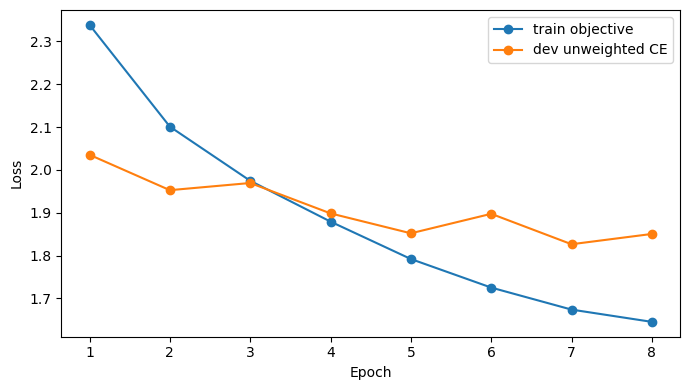

In [8]:
model, history, best_path = train_model(model, train_loader, dev_loader, label_names, optimizer)


Development metrics: {
  "loss": 1.8505614166235835,
  "macro_f1": 0.2582921118196965,
  "macro_precision": 0.29532280578131065,
  "macro_recall": 0.2650445266607059
}
                        precision    recall  f1-score   support

                  Fact       0.46      0.64      0.53       444
                 Issue       0.33      0.07      0.11        15
    ArgumentPetitioner       0.39      0.19      0.25       400
    ArgumentRespondent       0.38      0.17      0.23       272
               Statute       0.67      0.70      0.68       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.32      0.36      0.34       254
PrecedentNotReliedUpon       0.13      0.24      0.17        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0.36      0.10      0.15       102
    RatioOfTheDecision       0.30      0.44      0.36       403
  RulingByPresentCourt       0.33      0.37      0.35        49

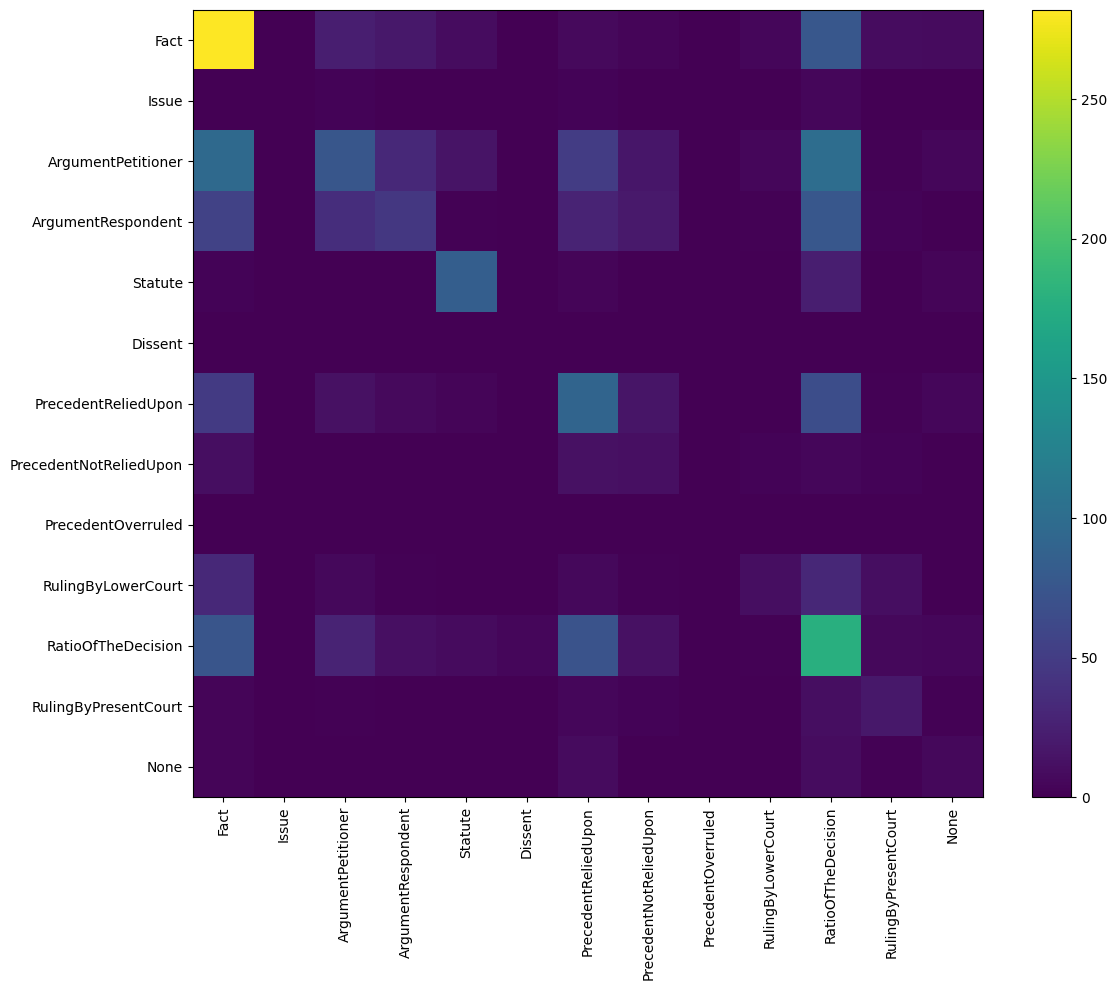

CL development metrics: {
  "loss": 1.8133161454901825,
  "macro_f1": 0.21586799891927505,
  "macro_precision": 0.23877622840523924,
  "macro_recall": 0.24147348548792996
}
IT development metrics: {
  "loss": 1.9202590017472132,
  "macro_f1": 0.278658695270382,
  "macro_precision": 0.32174818004851935,
  "macro_recall": 0.26604500757510785
}


In [9]:
metrics, gold, pred = evaluate(model, dev_loader, len(label_names))
print('Development metrics:', json.dumps(metrics, indent=2))
print(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
with open(OUTPUT_DIR / 'dev_report.txt', 'w', encoding='utf-8') as f:
    f.write(classification_report(gold, pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))
cm = confusion_matrix(gold, pred, labels=list(range(len(label_names))))
plt.figure(figsize=(12, 10))
plt.imshow(cm, aspect='auto')
plt.xticks(range(len(label_names)), label_names, rotation=90)
plt.yticks(range(len(label_names)), label_names)
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'dev_confusion_matrix.png', dpi=150)
plt.show()


# Domain-specific diagnostics (checkpoint selection still uses the combined dev set).
for domain_name, domain_rows in [('CL', data['CL_dev']), ('IT', data['IT_dev'])]:
    domain_records = records_from_payload(domain_rows, True)
    domain_loader = DataLoader(RRDataset(domain_records, tokenizer, label_to_id, True), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_rr)
    domain_metrics, domain_gold, domain_pred = evaluate(model, domain_loader, len(label_names))
    print(f'{domain_name} development metrics:', json.dumps(domain_metrics, indent=2))
    with open(OUTPUT_DIR / f'{domain_name.lower()}_dev_report.txt', 'w', encoding='utf-8') as f:
        f.write(classification_report(domain_gold, domain_pred, labels=list(range(len(label_names))), target_names=label_names, zero_division=0))


## 6. Generate test prediction JSON

Output maps each document ID to ordered official label strings, one per sentence.

In [10]:
# Submit the best development Macro-F1 LoRMA+ checkpoint. Preserve exact document IDs and sentence order.
import zipfile, shutil
pred_path = save_predictions(model, test_records, label_names, label_to_id, MODEL_FAMILY + '_lorma')
submission_path = OUTPUT_DIR / 'prediction.json'
with open(pred_path) as f: predictions = json.load(f)
expected = {}
for domain in keys:
    payload = data[domain + '_test']
    if isinstance(payload, list): docs = payload
    elif 'id' in payload and 'text' in payload: docs = [payload]
    else: docs = [dict(v, id=k) if isinstance(v, dict) else {'id': k, 'text': v} for k,v in payload.items()]
    for doc in docs:
        did = str(doc.get('id', doc.get('document_id', doc.get('doc_id', ''))))
        sentences = doc.get('text', doc.get('sentences', []))
        if isinstance(sentences, str): sentences = [sentences]
        if did in expected: raise ValueError(f'Duplicate test document: {did}')
        expected[did] = len(sentences)
        if not sentences: predictions[did] = []
assert set(predictions) == set(expected)
assert all(len(predictions[k]) == n for k,n in expected.items())
assert all(label in label_to_id for labels in predictions.values() for label in labels)
with open(submission_path, 'w', encoding='utf-8') as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(OUTPUT_DIR / 'submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(submission_path, arcname='prediction.json')
shutil.copy2(tokenizer_path, OUTPUT_DIR / 'custom_bpe_scratch.json')
print('LoRMA+ predictions:', submission_path)
print('Submission ZIP:', OUTPUT_DIR / 'submission.zip')
print('LoRMA+ checkpoint:', best_path)


LoRMA+ predictions: /kaggle/working/phase3_rr_model4_lorma/prediction.json
Submission ZIP: /kaggle/working/phase3_rr_model4_lorma/submission.zip
LoRMA+ checkpoint: /kaggle/working/phase3_rr_model4_lorma/best_rr_checkpoint.pt


## Corrections, evaluation, and reproducibility

- Corrected LoRMA+ matrix multiplication and output-space adapter dimensions, including rectangular GQA K/V projections. Source: Bihany, Patel & Modi (2025), section 3.2.2, equation (8): https://aclanthology.org/2025.findings-acl.527.pdf.
- The backbone stays frozen; only LoRMA A/B parameters and the classification head train. No PEFT adapter library is used.
- Fixed the undefined previous-sentence-context flag. Inputs preserve the target sentence's beginning and end when it exceeds the token budget.
- Manual attention, softmax, RoPE, RMSNorm, GELU and cross-entropy; no SDPA, FlashAttention, MultiheadAttention or built-in Transformer. Basic PyTorch layers, autograd, checkpointing and AdamW are used.
- FP32 score multiplication and RMSNorm statistics improve mixed-precision stability. Gradient checkpointing reduces activation memory.
- Train-only bounded inverse-square-root class weights, effective batch size 16, 8 maximum epochs, warm-up/cosine learning rates, and patience 3. These are starting choices, not measured optimal settings.
- Best checkpoint is selected using development Macro-F1 over all official labels. CL/IT reports and confusion matrix are saved; no test labels are used.
- `best_rr_checkpoint.pt` contains all frozen and adapted weights, labels and configuration. `load_lorma_checkpoint` reconstructs the adapter layout for strict loading. Keep the notebook/model definitions and copied tokenizer with it.
- `submission.zip` contains `prediction.json` at its root. Export validates document coverage, sentence counts, and label vocabulary, including empty documents.
- CPU tests use a small randomly initialized model and synthetic examples. Full Phase-1 checkpoint compatibility, Kaggle GPU memory usage and actual F1 still require the real training run; no high-F1 guarantee is made.
- This is one LORMA experiment. It does not replace the separate mandatory knowledge-distillation experiment or the course's remaining architecture/technique requirements.
